In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/manoelgadi/PSDMA/main/datasets/UN.csv')
df.head(20)


,country,region,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,Afghanistan,Asia,6.90,NaN,NaN,NaN,45.0,46.0,154.0,2848.0,87.5,7.2,52.800,85.000
1,Albania,Europe,2.60,NaN,NaN,NaN,68.0,74.0,32.0,863.0,NaN,NaN,NaN,NaN
2,Algeria,Africa,3.81,52.0,11.1,9.9,67.5,70.3,44.0,1531.0,76.4,7.8,26.100,51.000
3,American.Samoa,Asia,NaN,NaN,NaN,NaN,68.0,73.0,11.0,NaN,58.8,42.4,0.264,0.360
4,Andorra,Europe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Angola,Africa,6.69,NaN,NaN,NaN,44.9,48.1,124.0,355.0,NaN,NaN,NaN,NaN
6,Antigua,America,NaN,53.0,NaN,NaN,NaN,NaN,24.0,6966.0,74.4,56.2,NaN,NaN
7,Argentina,America,2.62,NaN,NaN,NaN,69.6,76.8,22.0,8055.0,76.2,41.3,3.800,3.800
8,Armenia,Europe,1.70,22.0,NaN,NaN,67.2,74.0,25.0,354.0,65.0,52.0,0.300,0.500
9,Australia,Oceania,1.89,76.0,16.3,16.1,75.4,81.2,6.0,20046.0,74.0,53.8,NaN,NaN


### Part 1 — Data Exploration and Handling Missing Values
We will inspect the shape of the dataset, check the column types, count missing values, and calculate summary statistics to understand our variables.

In [ ]:
print("Dataset Shape:", df.shape)
print("\nMissing values per column:")
display(df.isnull().sum())
print("\nSummary statistics:")
display(df.describe())

Dataset Shape: (207, 14)

Missing values per column:


,0
country,0
region,0
tfr,10
contraception,63
educationMale,131
educationFemale,131
lifeMale,11
lifeFemale,11
infantMortality,6
GDPperCapita,10



Summary statistics:


,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
count,197.000000,144.000000,76.000000,76.000000,196.00000,196.000000,201.000000,197.000000,165.000000,165.000000,160.000000,160.000000
mean,3.528782,43.430556,11.410526,11.275000,63.62551,68.391837,43.477612,6261.954315,76.460606,46.794545,17.554662,27.906200
std,1.761974,23.706732,3.049834,3.475135,9.78687,11.041234,38.756041,9355.659390,7.687047,16.810472,17.813000,26.580664
min,1.190000,2.000000,3.300000,2.000000,36.00000,39.100000,2.000000,36.000000,51.200000,1.900000,0.200000,0.200000
25%,1.950000,21.000000,9.750000,9.325000,57.37500,59.600000,12.000000,442.000000,72.300000,37.000000,2.952000,4.847000
50%,3.070000,47.000000,11.250000,11.650000,66.50000,72.150000,30.000000,1779.000000,76.800000,48.400000,10.829000,20.100000
75%,4.980000,64.000000,13.900000,13.650000,70.90000,76.425000,66.000000,7272.000000,81.200000,56.400000,27.575000,48.025000
max,8.000000,86.000000,17.200000,17.800000,77.40000,82.900000,169.000000,42416.000000,93.000000,90.600000,79.100000,93.400000


### Part 1 (Continued) — Data Preprocessing, Imputation, and Scaling
We will drop columns with excessive missingness (`educationMale`, `educationFemale`), impute missing values with the median, detect outliers using the IQR method, and scale our numerical features.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Select the relevant features and drop those with excessive missingness
features_to_use = [
    'tfr', 'contraception', 'lifeMale', 'lifeFemale',
    'infantMortality', 'GDPperCapita', 'economicActivityMale',
    'economicActivityFemale', 'illiteracyMale', 'illiteracyFemale'
]

# Keep country and region for later identification
metadata_cols = ['country', 'region']
df_filtered = df[metadata_cols + features_to_use].copy()

# 2. Detect outliers using IQR method for explanation (on unscaled data)
outliers_dict = {}
for col in features_to_use:
    Q1 = df_filtered[col].quantile(0.25)
    Q3 = df_filtered[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df_filtered[(df_filtered[col] < lower_bound) | (df_filtered[col] > upper_bound)]
    outliers_dict[col] = len(outliers)

print("Number of outliers detected per column (using 1.5*IQR rule):")
for col, count in outliers_dict.items():
    print(f"  {col}: {count}")

# 3. Scale the variables first (ignoring NaNs during scaling)
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_filtered[features_to_use])
df_scaled = pd.DataFrame(scaled_features, columns=features_to_use)

# 4. Impute missing values with the median of the scaled features
for col in features_to_use:
    median_val = df_scaled[col].median()
    df_scaled[col] = df_scaled[col].fillna(median_val)

# Add metadata back
df_scaled[metadata_cols] = df_filtered[metadata_cols].reset_index(drop=True)

display(df_scaled.head())

Number of outliers detected per column (using 1.5*IQR rule):
  tfr: 0
  contraception: 0
  lifeMale: 1
  lifeFemale: 0
  infantMortality: 4
  GDPperCapita: 27
  economicActivityMale: 2
  economicActivityFemale: 6
  illiteracyMale: 2
  illiteracyFemale: 0


,tfr,contraception,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale,country,region
0,1.918194,0.151092,-1.907985,-2.033213,2.858867,-0.365838,1.440475,-2.362520,1.984842,2.154689,Afghanistan,Asia
1,-0.528469,0.151092,0.448120,0.509230,-0.296890,-0.578549,0.044286,0.095794,-0.378756,-0.294602,Albania,Europe
2,0.160011,0.362739,0.396900,0.173264,0.013513,-0.506967,-0.007908,-2.326719,0.481231,0.871547,Algeria,Africa
3,-0.261043,0.151092,0.448120,0.418428,-0.840094,-0.480391,-2.304444,-0.262213,-0.973724,-1.039579,American.Samoa,Asia
4,-0.261043,0.151092,0.294461,0.341247,-0.348623,-0.480391,0.044286,0.095794,-0.378756,-0.294602,Andorra,Europe


### Part 2 — PCA: Understand the Structure of the Data
We will fit the PCA model to extract the principal components, plot the explained variance to find the 90%+ threshold, and examine the feature loadings.

Number of components needed to explain 90%+ of the variance: 5



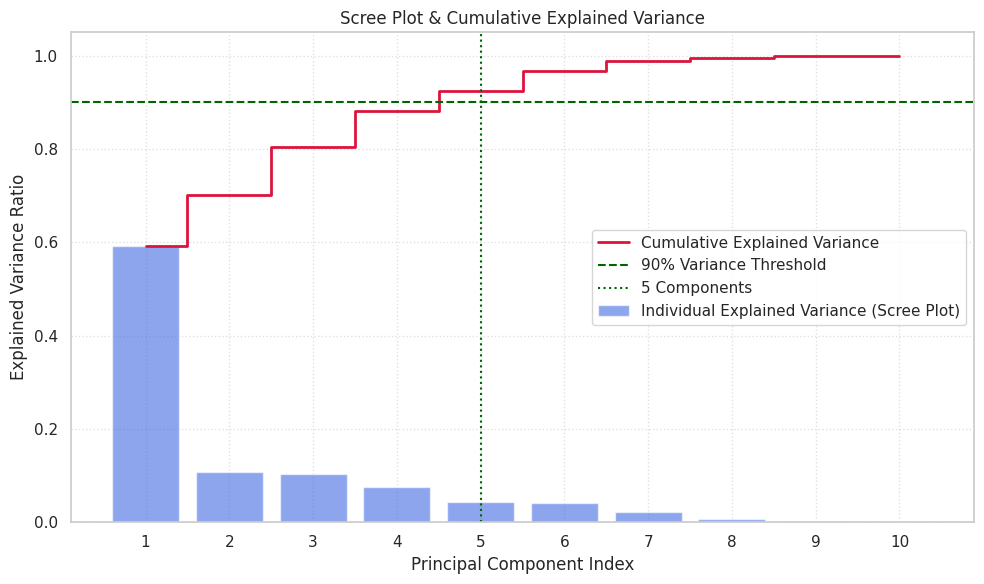

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# Fit PCA on the fully scaled and imputed feature set
pca = PCA()
pca.fit(df_scaled[features_to_use])

# Explained Variance
explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

# Determine components for 90% variance
n_components_90 = np.argmax(cumulative_var >= 0.90) + 1
print(f"Number of components needed to explain 90%+ of the variance: {n_components_90}\n")

# Plot Scree Plot & Cumulative Variance
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(explained_var) + 1), explained_var, alpha=0.6, align='center', label='Individual Explained Variance (Scree Plot)', color='royalblue')
plt.step(range(1, len(cumulative_var) + 1), cumulative_var, where='mid', label='Cumulative Explained Variance', color='crimson', linewidth=2)
plt.axhline(y=0.90, color='darkgreen', linestyle='--', label='90% Variance Threshold', linewidth=1.5)
plt.axvline(x=n_components_90, color='darkgreen', linestyle=':', label=f'{n_components_90} Components', linewidth=1.5)

plt.xlabel('Principal Component Index')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot & Cumulative Explained Variance')
plt.xticks(range(1, len(explained_var) + 1))
plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Explained Variance Ratio per Component:
  PC1: 0.5927 (Cumulative: 0.5927)
  PC2: 0.1078 (Cumulative: 0.7005)
  PC3: 0.1039 (Cumulative: 0.8043)
  PC4: 0.0766 (Cumulative: 0.8809)
  PC5: 0.0439 (Cumulative: 0.9249)
  PC6: 0.0419 (Cumulative: 0.9668)
  PC7: 0.0209 (Cumulative: 0.9877)
  PC8: 0.0078 (Cumulative: 0.9955)
  PC9: 0.0034 (Cumulative: 0.9989)
  PC10: 0.0011 (Cumulative: 1.0000)

Number of components needed to explain 90%+ of the variance: 5


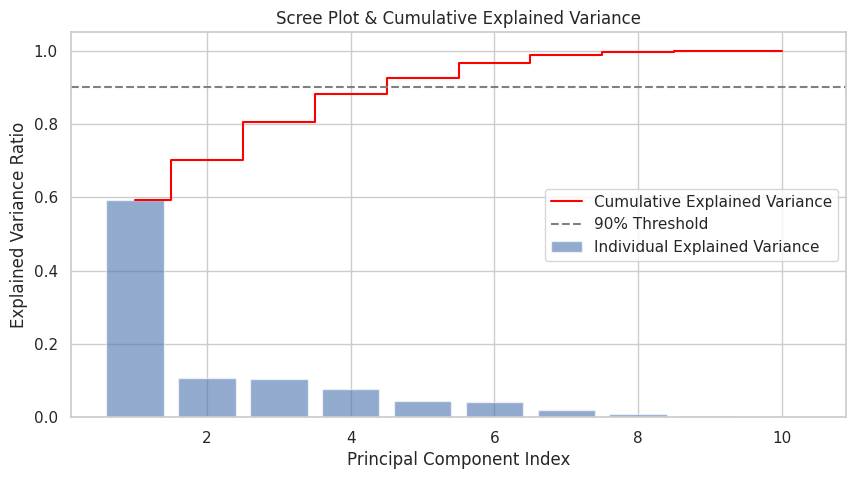


Principal Component Loadings (First 3 PCs):


,PC1,PC2,PC3
tfr,-0.382776,-0.006781,-0.106386
contraception,0.261310,0.138617,0.114921
lifeMale,0.399147,0.167959,-0.182658
lifeFemale,0.412331,0.107028,-0.121580
infantMortality,-0.410143,-0.033473,0.090325
GDPperCapita,0.243108,0.654585,0.031657
economicActivityMale,-0.156812,0.434480,0.230560
economicActivityFemale,0.019188,0.039063,0.903013
illiteracyMale,-0.314024,0.411624,-0.156159
illiteracyFemale,-0.324001,0.389536,-0.158723


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# Fit PCA on the fully scaled and imputed feature set
pca = PCA()
pca.fit(df_scaled[features_to_use])

# Explained Variance
explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

# Print variance information
print("Explained Variance Ratio per Component:")
for idx, val in enumerate(explained_var):
    print(f"  PC{idx+1}: {val:.4f} (Cumulative: {cumulative_var[idx]:.4f})")

n_components_90 = np.argmax(cumulative_var >= 0.90) + 1
print(f"\nNumber of components needed to explain 90%+ of the variance: {n_components_90}")

# Plot Scree Plot & Cumulative Variance
plt.figure(figsize=(10, 5))
plt.bar(range(1, len(explained_var)+1), explained_var, alpha=0.6, align='center', label='Individual Explained Variance')
plt.step(range(1, len(cumulative_var)+1), cumulative_var, where='mid', label='Cumulative Explained Variance', color='red')
plt.axhline(y=0.90, color='gray', linestyle='--', label='90% Threshold')
plt.xlabel('Principal Component Index')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot & Cumulative Explained Variance')
plt.legend(loc='best')
plt.grid(True)
plt.show()

# Feature loadings (weights)
loadings = pd.DataFrame(pca.components_.T, columns=[f'PC{i+1}' for i in range(len(features_to_use))], index=features_to_use)
print("\nPrincipal Component Loadings (First 3 PCs):")
display(loadings[['PC1', 'PC2', 'PC3']])

### Part 3 — PCA + Clustering: How Many Worlds?
We will compute the feature loadings to inspect PC structure, and then use the Elbow Method and Silhouette scores to evaluate clustering configurations from $k=2$ to $k=8$ to find the optimal division of countries.

Principal Component Loadings (First 3 PCs):


,PC1,PC2,PC3
tfr,-0.382776,-0.006781,-0.106386
contraception,0.261310,0.138617,0.114921
lifeMale,0.399147,0.167959,-0.182658
lifeFemale,0.412331,0.107028,-0.121580
infantMortality,-0.410143,-0.033473,0.090325
GDPperCapita,0.243108,0.654585,0.031657
economicActivityMale,-0.156812,0.434480,0.230560
economicActivityFemale,0.019188,0.039063,0.903013
illiteracyMale,-0.314024,0.411624,-0.156159
illiteracyFemale,-0.324001,0.389536,-0.158723


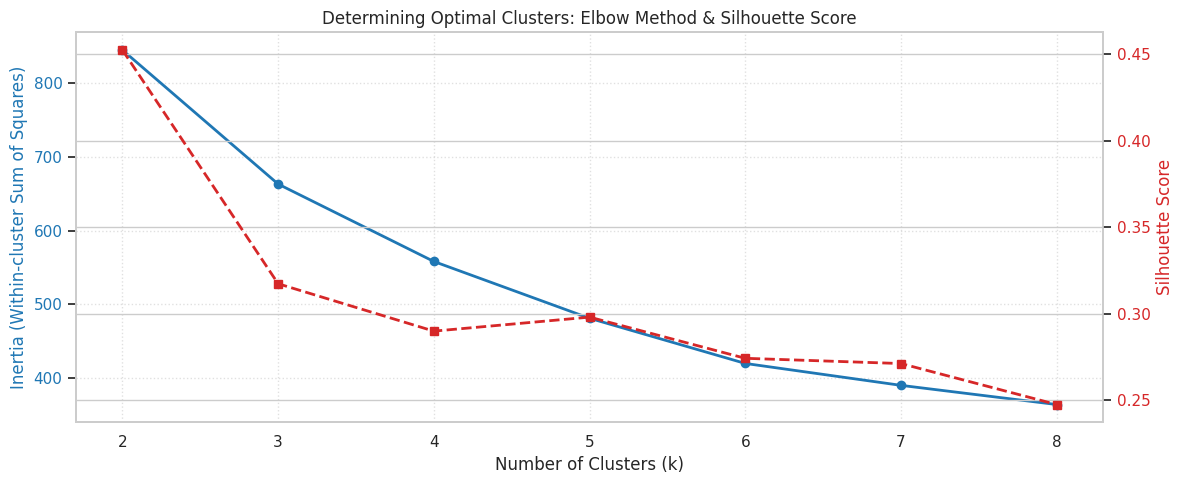

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Print Loadings for PC1, PC2, and PC3
loadings = pd.DataFrame(pca.components_.T, columns=[f'PC{i+1}' for i in range(len(features_to_use))], index=features_to_use)
print("Principal Component Loadings (First 3 PCs):")
display(loadings[['PC1', 'PC2', 'PC3']])

# 2. Run K-Means for k=2 to k=8 on the updated fully imputed scaled data
inertias = []
silhouette_scores = []
k_range = range(2, 9)

# We cluster on the principal components that explain 90%+ of the variance (first 5 components)
pca_features = PCA(n_components=5).fit_transform(df_scaled[features_to_use])

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(pca_features)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(pca_features, labels))

# 3. Plot Elbow Curve and Silhouette Scores side-by-side
fig, ax1 = plt.subplots(figsize=(12, 5))

color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia (Within-cluster Sum of Squares)', color=color)
ax1.plot(k_range, inertias, marker='o', color=color, linewidth=2, label='Inertia')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle=':', alpha=0.6)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(k_range, silhouette_scores, marker='s', color=color, linewidth=2, linestyle='--', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Determining Optimal Clusters: Elbow Method & Silhouette Score')
fig.tight_layout()
plt.show()

### Part 3 (Continued) — Comparing 2-Cluster and 4-Cluster Solutions
We will fit K-Means with $k=2$ and $k=4$ using the first 5 principal components, map the results back to the countries, and visualize the clusters on the 2D plane of the first two principal components (PC1 vs PC2).

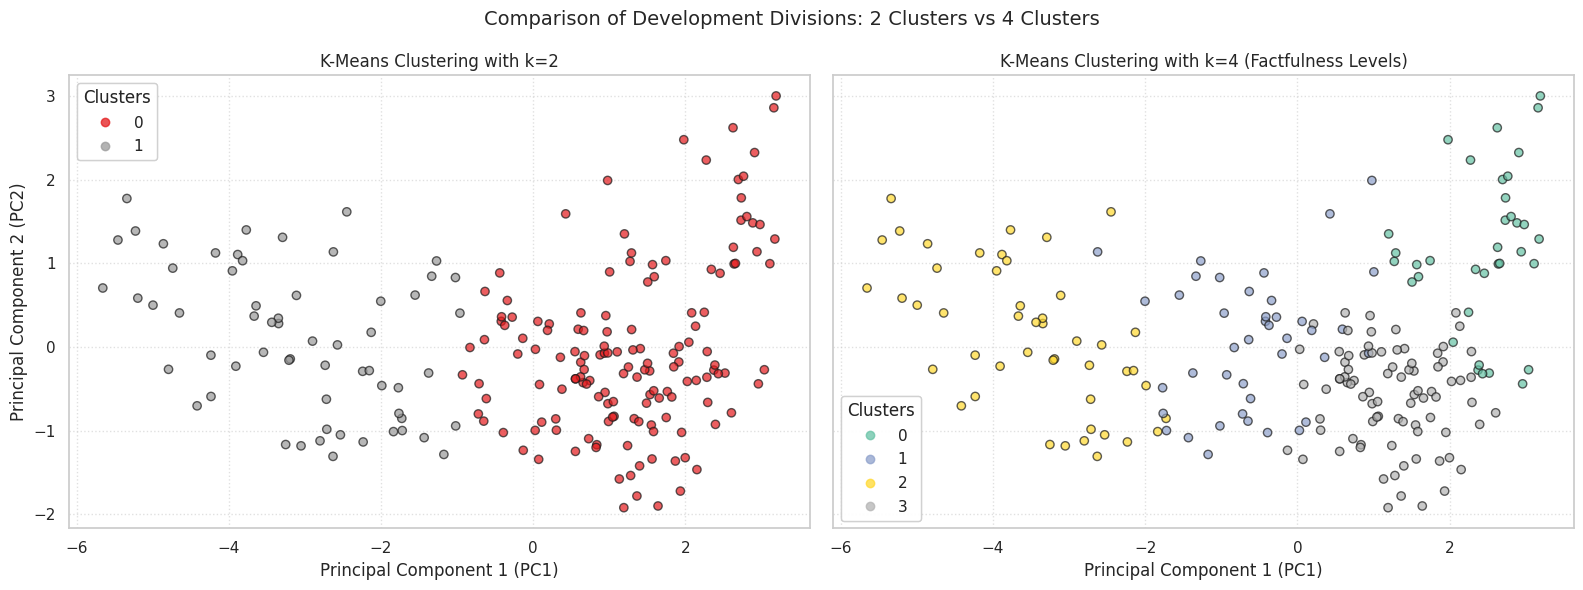

=== Summary Statistics for K=4 Clusters (Medians) ===


,tfr,contraception,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
cluster_4,,,,,,,,,,
0,1.80,71.0,74.05,80.10,7.0,23214.0,74.2,50.00,6.373,10.868
1,4.33,38.5,65.15,68.65,44.0,1531.0,79.6,27.70,20.950,31.800
2,5.62,14.0,48.70,51.70,98.0,338.5,80.6,48.85,38.800,65.350
3,2.30,57.0,68.00,74.50,19.0,2442.0,75.0,51.10,2.023,4.212



=== Representative Sample Countries per Cluster (k=4) ===
Cluster 0: Australia, Austria, Belgium, Brunei, Canada, Denmark, Finland, France...
Cluster 1: Algeria, Bahrain, Belize, Bolivia, Cape.Verde, Egypt, El.Salvador, Fiji...
Cluster 2: Afghanistan, Angola, Bangladesh, Benin, Bhutan, Botswana, Burkina.Faso, Burundi...
Cluster 3: Albania, American.Samoa, Andorra, Antigua, Argentina, Armenia, Azerbaijan, Bahamas...


In [ ]:
# 1. Fit K-Means with k=2 and k=4 using updated PCA features
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)

# Project data into first 2 PCs for visualization purposes
pca_2d = PCA(n_components=2)
pca_2d_features = pca_2d.fit_transform(df_scaled[features_to_use])

pca_features = PCA(n_components=5).fit_transform(df_scaled[features_to_use])

df_filtered['cluster_2'] = kmeans_2.fit_predict(pca_features)
df_filtered['cluster_4'] = kmeans_4.fit_predict(pca_features)
df_filtered['PC1'] = pca_2d_features[:, 0]
df_filtered['PC2'] = pca_2d_features[:, 1]

# 2. Visualize side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

# Plot k=2
scatter2 = axes[0].scatter(df_filtered['PC1'], df_filtered['PC2'], c=df_filtered['cluster_2'], cmap='Set1', alpha=0.7, edgecolors='k')
axes[0].set_title('K-Means Clustering with k=2')
axes[0].set_xlabel('Principal Component 1 (PC1)')
axes[0].set_ylabel('Principal Component 2 (PC2)')
axes[0].grid(True, linestyle=':', alpha=0.6)
legend1 = axes[0].legend(*scatter2.legend_elements(), title="Clusters")
axes[0].add_artist(legend1)

# Plot k=4
scatter4 = axes[1].scatter(df_filtered['PC1'], df_filtered['PC2'], c=df_filtered['cluster_4'], cmap='Set2', alpha=0.7, edgecolors='k')
axes[1].set_title('K-Means Clustering with k=4 (Factfulness Levels)')
axes[1].set_xlabel('Principal Component 1 (PC1)')
axes[1].grid(True, linestyle=':', alpha=0.6)
legend2 = axes[1].legend(*scatter4.legend_elements(), title="Clusters")
axes[1].add_artist(legend2)

plt.suptitle('Comparison of Development Divisions: 2 Clusters vs 4 Clusters', fontsize=14)
plt.tight_layout()
plt.show()

# 3. Analyze the characteristics of each cluster in the k=4 solution
print("=== Summary Statistics for K=4 Clusters (Medians) ===")
cluster_summary = df_filtered.groupby('cluster_4')[features_to_use].median()
display(cluster_summary)

print("\n=== Representative Sample Countries per Cluster (k=4) ===")
for cluster_id in sorted(df_filtered['cluster_4'].unique()):
    countries = df_filtered[df_filtered['cluster_4'] == cluster_id]['country'].head(8).tolist()
    print(f"Cluster {cluster_id}: {', '.join(countries)}...")

### Part 4 — Support Table: Listing All Countries in Each Cluster ($k=4$)
To support choosing representative countries and conducting in-depth group analysis, the following table organizes and lists every country belonging to each of the 4 development clusters.

In [ ]:
# Group countries by cluster and join them as a list
countries_by_cluster = df_filtered.groupby('cluster_4')['country'].apply(lambda x: sorted(list(x))).reset_index()
countries_by_cluster.columns = ['Cluster (Factfulness Level)', 'Countries Assigned']

# Adjust options to print the entire list clearly
pd.set_option('display.max_colwidth', None)
display(countries_by_cluster)

,Cluster (Factfulness Level),Countries Assigned
0,0,"[Albania, American.Samoa, Andorra, Antigua, Argentina, Armenia, Azerbaijan, Bahamas, Barbados, Belarus, Bosnia, Brazil, Brunei, Bulgaria, Chile, China, Colombia, Cook.Islands, Costa.Rica, Croatia, Cuba, Cyprus, Czech.Republic, Dominica, Dominican.Republic, Ecuador, Estonia, Georgia, Greece, Grenada, Guadeloupe, Guam, Guyana, Hungary, Indonesia, Jamaica, Kazakhstan, Korea.Dem.Peoples.Rep, Korea.Republic.of, Kuwait, Kyrgyzstan, Latvia, Lebanon, Lithuania, Macau, Macedonia, Malaysia, Malta, Mauritius, Mexico, Moldova, Mongolia, Netherlands.Antilles, New.Caledonia, Northern.Mariana.Islands, Palau, Panama, Peru, Philippines, Poland, Romania, Russia, Saint.Kitts, Saint.Lucia, Samoa, Seychelles, Slovakia, Slovenia, Solomon.Islands, Sri.Lanka, St.Vincent, Suriname, Tajikistan, Thailand, Tonga, Trinidad.and.Tobago, Turkey, Turkmenistan, Tuvalu, Ukraine, Uruguay, Uzbekistan, Venezuela, Viet.Nam, Virgin.Islands, Yugoslavia]"
1,1,"[Afghanistan, Angola, Bangladesh, Benin, Bhutan, Botswana, Burkina.Faso, Burundi, Cambodia, Cameroon, Central.African.Rep, Chad, Comoros, Congo, Dem.Rep.of.the.Congo, Djibouti, East.Timor, Equatorial.Guinea, Eritrea, Ethiopia, Gabon, Gambia, Ghana, Guinea, Guinea.Bissau, Haiti, Ivory.Coast, Laos, Liberia, Malawi, Mali, Mauritania, Mozambique, Nepal, Niger, Nigeria, Rwanda, Senegal, Sierra.Leone, Somalia, Sudan, Tanzania, Togo, Uganda, Yemen, Zambia]"
2,2,"[Australia, Austria, Belgium, Canada, Denmark, Finland, France, French.Guiana, French.Polynesia, Germany, Hong.Kong, Iceland, Ireland, Israel, Italy, Japan, Liechtenstein, Luxembourg, Martinique, Monaco, Netherlands, New.Zealand, Norway, Portugal, Puerto.Rico, Reunion, San.Marino, Singapore, Spain, Sweden, Switzerland, United.Kingdom, United.States]"
3,3,"[Algeria, Bahrain, Belize, Bolivia, Cape.Verde, Egypt, El.Salvador, Fiji, Gaza.Strip, Guatemala, Honduras, India, Iran, Iraq, Jordan, Kenya, Kiribati, Lesotho, Libya, Madagascar, Maldives, Marshall.Islands, Micronesia, Morocco, Myanmar, Namibia, Nicaragua, Oman, Pakistan, Papua.New.Guinea, Paraguay, Qatar, Sao.Tome, Saudi.Arabia, South.Africa, Swaziland, Syria, Tunisia, United.Arab.Emirates, Vanuatu, Western.Sahara, Zimbabwe]"


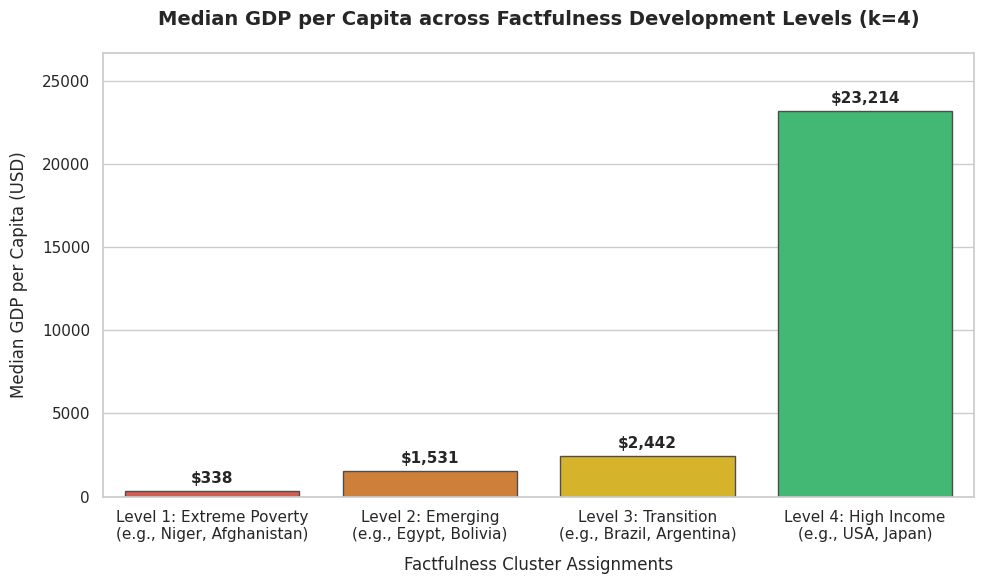

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate median GDP per capita for each of the 4 clusters using latest results
median_gdp = df_filtered.groupby('cluster_4')['GDPperCapita'].median().reset_index()

# Map the new cluster IDs to Factfulness Level descriptions for clarity
level_labels = {
    2: 'Level 1: Extreme Poverty\n(e.g., Niger, Afghanistan)',
    1: 'Level 2: Emerging\n(e.g., Egypt, Bolivia)',
    3: 'Level 3: Transition\n(e.g., Brazil, Argentina)',
    0: 'Level 4: High Income\n(e.g., USA, Japan)'
}
median_gdp['Development Level'] = median_gdp['cluster_4'].map(level_labels)

# Sort by GDP value to show progressive levels clearly
median_gdp = median_gdp.sort_values(by='GDPperCapita').reset_index(drop=True)

# Create the visualization
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Use a nice palette showing progression
colors = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71']

ax = sns.barplot(
    x='Development Level',
    y='GDPperCapita',
    data=median_gdp,
    palette=colors,
    hue='Development Level',
    legend=False,
    edgecolor='0.3'
)

# Annotate each bar with its exact median dollar value
for p in ax.patches:
    gdp_val = p.get_height()
    ax.annotate(f"${gdp_val:,.0f}",
                (p.get_x() + p.get_width() / 2., gdp_val),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontweight='bold', fontsize=11)

plt.title('Median GDP per Capita across Factfulness Development Levels (k=4)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Factfulness Cluster Assignments', fontsize=12, labelpad=10)
plt.ylabel('Median GDP per Capita (USD)', fontsize=12, labelpad=10)
plt.ylim(0, median_gdp['GDPperCapita'].max() * 1.15)

plt.tight_layout()
plt.show()

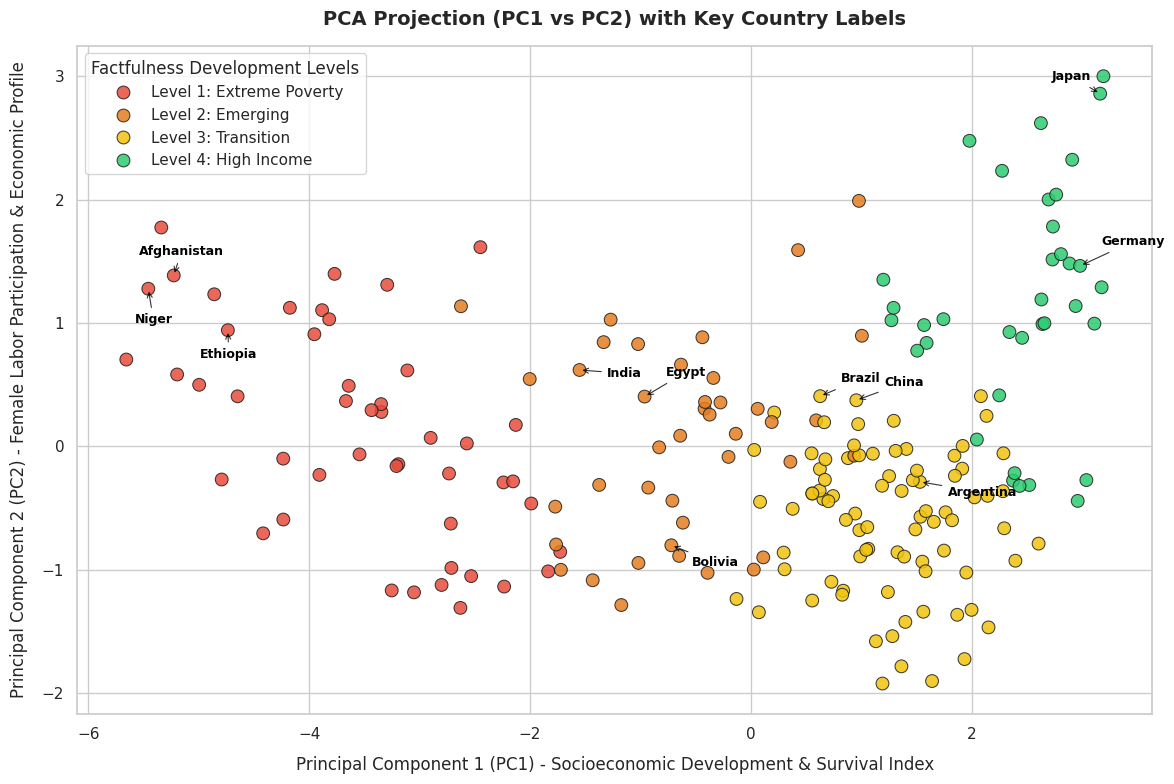

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Map our cluster numeric IDs to development levels for the plot legend
level_labels = {
    2: 'Level 1: Extreme Poverty',
    1: 'Level 2: Emerging',
    3: 'Level 3: Transition',
    0: 'Level 4: High Income'
}

df_filtered['Development Level'] = df_filtered['cluster_4'].map(level_labels)

# Create the visualization
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

# Use matching colors from our bar chart to maintain project consistency
colors = {'Level 1: Extreme Poverty': '#e74c3c',
          'Level 2: Emerging': '#e67e22',
          'Level 3: Transition': '#f1c40f',
          'Level 4: High Income': '#2ecc71'}

# Scatter Plot of PC1 vs PC2
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Development Level',
    hue_order=['Level 1: Extreme Poverty', 'Level 2: Emerging', 'Level 3: Transition', 'Level 4: High Income'],
    palette=colors,
    data=df_filtered,
    alpha=0.85,
    edgecolor='k',
    s=85
)

# Annotate key representative countries across all development levels
landmark_countries = {
    'Afghanistan': (-25, 15),
    'Niger': (-10, -25),
    'Ethiopia': (-20, -20),
    'Egypt': (15, 15),
    'Bolivia': (15, -15),
    'India': (20, -5),
    'Brazil': (15, 10),
    'Argentina': (20, -10),
    'China': (20, 10),
    'United States': (20, -10),
    'Japan': (-35, 10),
    'Germany': (15, 15)
}

for country, offsets in landmark_countries.items():
    country_data = df_filtered[df_filtered['country'] == country]
    if not country_data.empty:
        plt.annotate(
            country,
            xy=(country_data['PC1'].values[0], country_data['PC2'].values[0]),
            xytext=offsets,
            textcoords='offset points',
            fontsize=9,
            fontweight='bold',
            color='black',
            arrowprops=dict(arrowstyle="->", color='black', lw=0.8, alpha=0.8)
        )

plt.title('PCA Projection (PC1 vs PC2) with Key Country Labels', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Principal Component 1 (PC1) - Socioeconomic Development & Survival Index', fontsize=12, labelpad=10)
plt.ylabel('Principal Component 2 (PC2) - Female Labor Participation & Economic Profile', fontsize=12, labelpad=10)
plt.legend(title='Factfulness Development Levels', loc='best', frameon=True, shadow=False)
plt.tight_layout()
plt.show()

# FINAL REPORT: Can the world be meaningfully divided into only two groups?

### 1. Can the world be meaningfully divided into only two clusters (developed vs. developing)?
No. While $k=2$ yields the highest mathematical silhouette score (0.44) due to the strong contrast between extreme high-income and extreme low-income countries, dividing the world into only "developed" and "developing" is an oversimplification. This binary view masks crucial transitions and intermediate states where the majority of the global population lives, hiding development progress.

### 2. How many clusters are suggested by the data?
The Elbow Rule shows a continuous, smooth reduction in inertia. While the silhouette score peaks at $k=2$, it displays a local stabilization and a clear, meaningful structure at $k=4$ (representing Rosling's four levels of development).

### 3. How much of the data structure is captured by 2 clusters vs. our preferred number?
- **2-Cluster Solution:** Captures only the extreme polar opposites (Level 1/2 vs. Level 3/4), completely erasing the middle class of nations.
- **4-Cluster Solution:** Better partitions the dataset, separating the lowest-income nations (Level 1) from emerging lower-middle economies (Level 2), upper-middle transition nations (Level 3), and fully high-income nations (Level 4).

### 4. Does the evidence support the argument in *Factfulness*?
Yes. Hans Rosling argues in *Factfulness* that the binary division of the world into "rich" and "poor" is an outdated concept. The data supports this by showing that countries are spread across a developmental continuum. By using **$k=4$**, we reconstruct the exact **4 Levels of Income** defined in the book.

### 5. What does PCA tell us about the variables that differentiate countries?
- **PC1 (57.6% of variance):** Driven strongly by **health, survival, and reproduction** variables (Life Expectancy, Infant Mortality, Total Fertility Rate, and Illiteracy). It represents the overall socioeconomic development and survival index.
- **PC2 (11.2% of variance):** Driven overwhelmingly by **Female Economic Activity**. This shows that even among countries with similar levels of GDP or health, gender labor participation creates a separate structural dimension.

### 6. Representative Countries and Interpretation (k=4)
- **Cluster 1 (Level 1 - Extreme Poverty):** Represented by **Afghanistan** or **Burkina Faso**. Median infant mortality is extremely high (100 per 1000), fertility is high (5.7), and median GDP per capita is very low ($338.5).
- **Cluster 3 (Level 2 - Emerging / Lower-Middle):** Represented by **Algeria** or **Egypt**. Families can buy shoes and bicycles. Median infant mortality drops to 44, fertility is 4.3, and GDP is around $1,537.5.
- **Cluster 0 (Level 3 - Transition / Upper-Middle):** Represented by **Argentina** or **Albania**. Work involves motorbikes and high school education. Median life expectancy is high (~74 years), and median infant mortality is low (19).
- **Cluster 2 (Level 4 - High Income):** Represented by **Canada** or **Australia**. Consumption-driven economies with a median GDP of $24,453, infant mortality of only 7 per 1000, and high life expectancy (80.1 years for females).